## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Dataset structure

| Column Name | Description |
| :--- | :--- |
| **uid** | Unique identifier for each row. |
| **asin** | Product ID from Amazon. |
| **title** | Title of the product. |
| **stars** | Product rating. If 0, no ratings were found. |
| **reviews** | Number of customer reviews. If 0, no ratings were found. |
| **price** | Price of the product. (Currency: GBP) |
| **isBestSeller** | Product category indicator/Best seller status. |
| **boughtInLastMonth** | Whether the product was bought in the last month. |
| **category** | Indicates products category. |



## Download the Dataset

In [1]:

import kagglehub
from kagglehub import KaggleDatasetAdapter
from IPython.display import clear_output

# Filepath to the dataset
file_path = "amz_uk_price_prediction_dataset.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "asaniczka/uk-optimal-product-price-prediction",
  file_path,
)

clear_output()
print("Dataset loaded successfully!")


Dataset loaded successfully!


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
categorical_df = df.select_dtypes(exclude="number")
numeric_df = df.select_dtypes(include="number")

In [4]:
print(categorical_df.shape)
print(numeric_df.shape)

(2443651, 4)
(2443651, 5)


In [5]:
categorical_df.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='str')

In [6]:
# A table showing the frequency of occurrences for combinations 
# of the two categorical variables: category and isBestSeller
crosstab_norm = pd.crosstab(categorical_df.category, categorical_df.isBestSeller, normalize="index")
display(crosstab_norm)

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


The Top categories that have the most best sellers: 

In [7]:
# Top 5: Normalized
crosstab_norm_sorted = crosstab_norm.sort_values(True, ascending=False)
crosstab_norm_sorted[:5]

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339


In [8]:
categories = ", ".join(crosstab_norm_sorted[:5].index.to_list())
print(f"The categories that being a best seller seem more prevelent are: {categories}")

The categories that being a best seller seem more prevelent are: Grocery, Smart Home Security & Lighting, Health & Personal Care, Mobile Phone Accessories, Power & Hand Tools


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.


In [9]:
# chi-square
from scipy.stats import chi2_contingency

crosstab = pd.crosstab(categorical_df.category, categorical_df.isBestSeller)

_, chi2_pvalue, _, _  = chi2_contingency(crosstab)


# If the p value is smaller than 0.05 (or alpha) we do have a correlation between 2 categorical variables
# Else, nothigness
alpha = 0.05
if chi2_pvalue <= alpha:
    print(f"The p value is: {chi2_pvalue} which is lower than the alpha {alpha}. There is evidence of correlation between category and isBestSeller.")
else:
    print("No correlation found!")


The p value is: 0.0 which is lower than the alpha 0.05. There is evidence of correlation between category and isBestSeller.


In [10]:
# Cramer's V
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
cramer_v = association(crosstab, method='cramer')

if cramer_v <0.10:
    string = "negligible / very weak association"
elif cramer_v < 0.20:
    string = "weak association"
elif cramer_v < 0.3:
    string = "moderate association"
elif cramer_v < 0.5:
    string = "strong association"
else:
    string = "very strong association"

phrase = f"There is a {string} between the category and being a best-seller."

print(phrase)


There is a weak association between the category and being a best-seller.



3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [11]:
df.category.nunique()

296

In [12]:
crosstab_norm.sort_values(True, ascending=False)[:15]

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


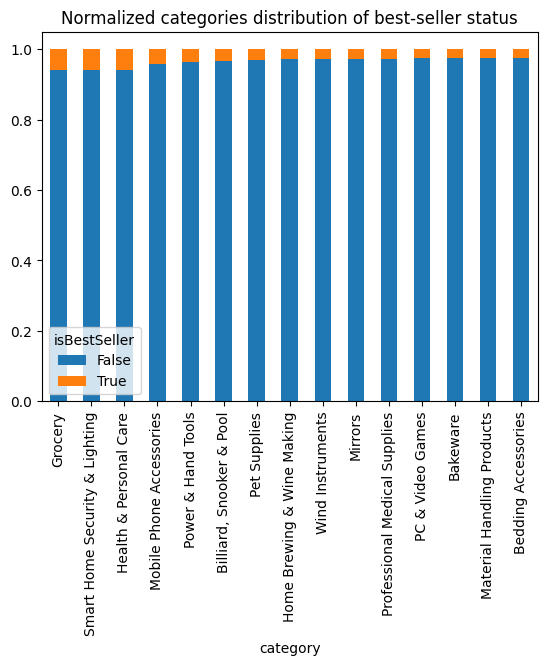

In [13]:
import matplotlib.pyplot as plt

crosstab_cat_bestseller = crosstab_norm.sort_values(True, ascending=False)[:15]
ax = crosstab_cat_bestseller.plot(kind='bar', stacked=True)
ax.set_title("Normalized categories distribution of best-seller status")
plt.show()

---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.


In [14]:
def filter_outliers(data, column = "price"):


    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print("Lower bound: ", lower_bound)
    print("Upper bound: ", upper_bound)

    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

    return filtered_data



In [15]:
filtered_price = filter_outliers(numeric_df)
filtered_df = filtered_price.join(df.category)
filtered_df

Lower bound:  -44.01
Upper bound:  99.99000000000001


,uid,stars,reviews,price,boughtInLastMonth,category
0,1,4.7,15308,21.99,0,Hi-Fi Speakers
1,2,4.7,98099,23.99,0,Hi-Fi Speakers
2,3,4.7,15308,21.99,0,Hi-Fi Speakers
3,4,4.7,7205,31.99,0,Hi-Fi Speakers
4,5,4.6,1881,17.99,0,Hi-Fi Speakers
...,...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0,Motorbike Clothing
2443647,2828590,0.0,0,97.99,0,Motorbike Clothing
2443648,2828591,0.0,0,52.99,0,Motorbike Clothing
2443649,2828592,4.3,404,79.99,0,Motorbike Clothing


In [16]:
# Top 20 categories based on count

top_20_count= filtered_df["category"].value_counts()[:20]
display(top_20_count)

top_20_count_cat = top_20_count.index.to_list()
print(top_20_count_cat)

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
Name: count

['Sports & Outdoors', 'Beauty', 'Bath & Body', 'Manicure & Pedicure Products', 'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care', 'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor', 'Luggage and travel gear', 'Women', 'Fragrances', 'Handmade Kitchen & Dining', 'Handmade Artwork', 'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men', 'Baby']


In [17]:
count_price_df = filtered_df[filtered_df.category.isin(top_20_count_cat)][["category", "price"]]
count_price_df = count_price_df.dropna().sort_values("price")
count_price_df

,category,price
342871,Sports & Outdoors,0.00
1532255,Sports & Outdoors,0.00
1025782,Sports & Outdoors,0.00
1531995,Sports & Outdoors,0.00
1422882,Sports & Outdoors,0.00
...,...,...
123741,Handmade Gifts,99.99
900942,Sports & Outdoors,99.99
2026117,Sports & Outdoors,99.99
2105274,Sports & Outdoors,99.99


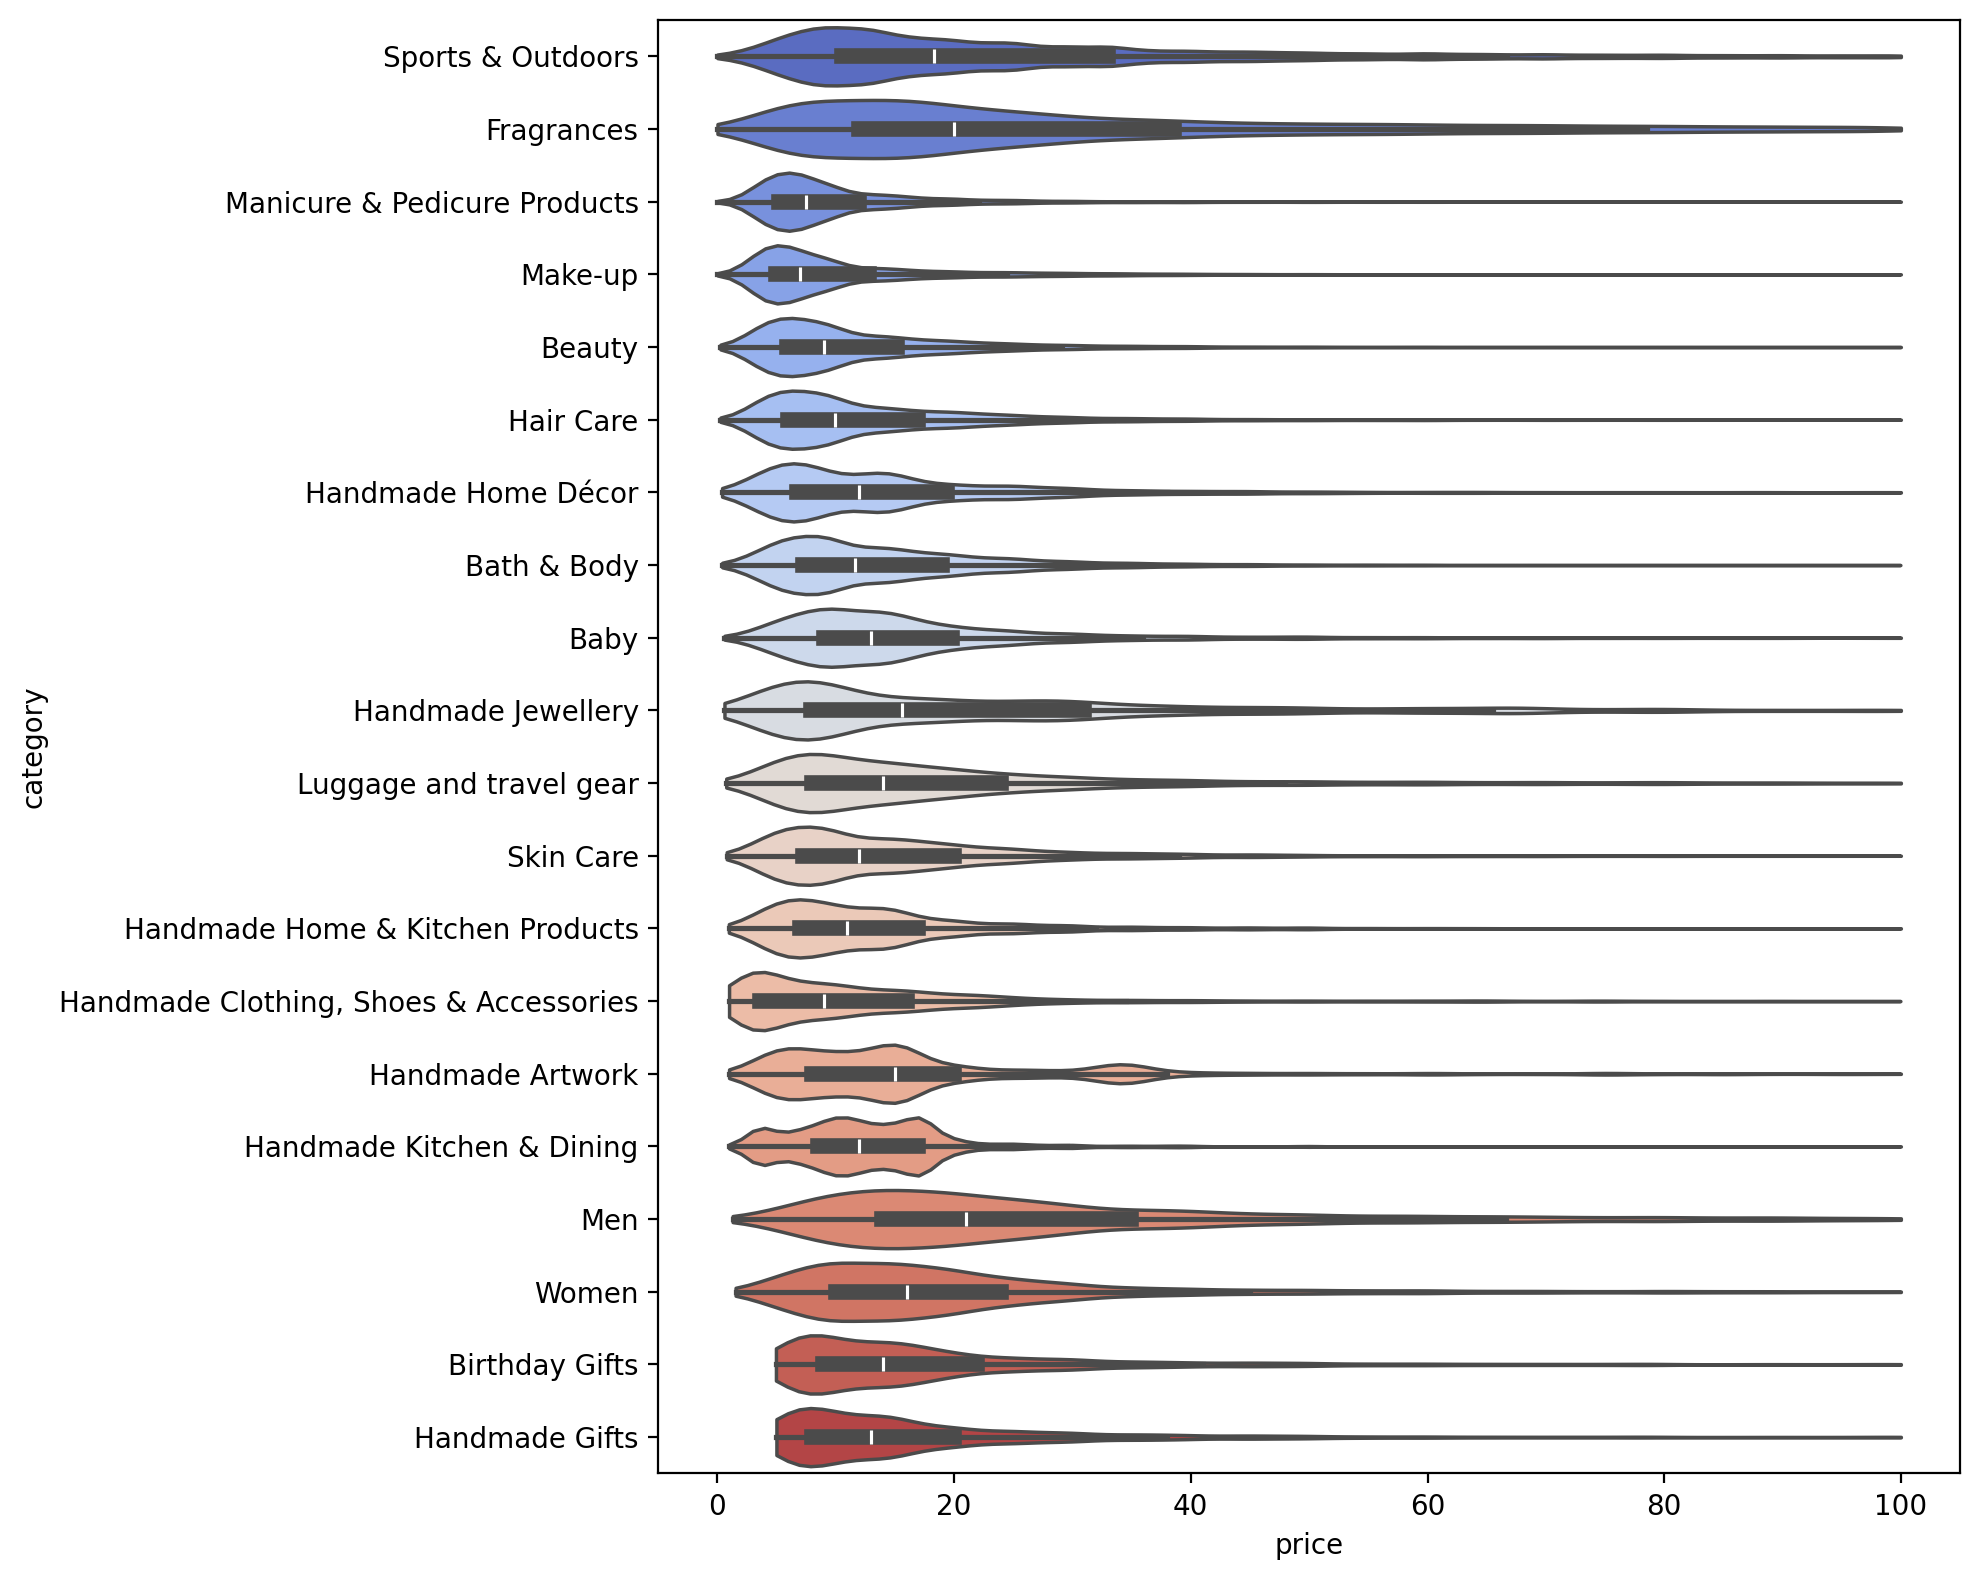

In [18]:
# Violin plots
import matplotlib.pylab as plt
%matplotlib inline
plt.rcParams['figure.dpi'] = 200
fig=plt.figure(figsize=(10, 8))

sns.violinplot(data=count_price_df,
                y="category",
                x="price",
                palette="coolwarm",
                hue="category",
                legend=False,
                density_norm="count",
                cut = 0)

plt.tight_layout()
plt.show()

In [19]:
# Top 20 categories based on medium price

top_20_most_expensive_median= filtered_df.groupby("category").median().sort_values("price", ascending = False)[:20]
display(top_20_most_expensive_median)


,uid,stars,reviews,price,boughtInLastMonth
category,,,,,
Desktop PCs,2233906.0,4.0,5.0,74.000,0.0
Boxing Shoes,1836662.0,0.0,0.0,69.790,0.0
Tablets,1536287.5,0.0,0.0,69.000,0.0
Graphics Cards,348832.0,4.1,14.0,68.540,0.0
Motherboards,349351.5,4.4,89.5,67.920,0.0
Made in Italy Handmade,891334.0,0.0,0.0,64.000,0.0
Digital Frames,2581418.5,3.6,1.0,63.900,0.0
Streaming Clients,2817220.5,0.0,0.0,62.680,0.0
Golf Shoes,1830985.0,0.0,0.0,62.390,0.0


In [20]:
print(f"The price category that tends to have the highest median price is {top_20_most_expensive_median.iloc[0].name} with a median price of {top_20_most_expensive_median.iloc[0].price} pounds.")

The price category that tends to have the highest median price is Desktop PCs with a median price of 74.0 pounds.


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.


In [21]:
# Top 10 categories based on count

top_10_cat = top_20_count_cat[:10]
top_10_df = filtered_df[["category", "price"]][filtered_df.category.isin(top_10_cat)]

top_10_df

,category,price
82163,Sports & Outdoors,6.49
82164,Sports & Outdoors,49.99
82167,Sports & Outdoors,16.98
82168,Sports & Outdoors,19.95
82169,Sports & Outdoors,49.99
...,...,...
2429088,Sports & Outdoors,99.67
2429089,Sports & Outdoors,20.62
2429090,Sports & Outdoors,59.86
2437153,Sports & Outdoors,14.99


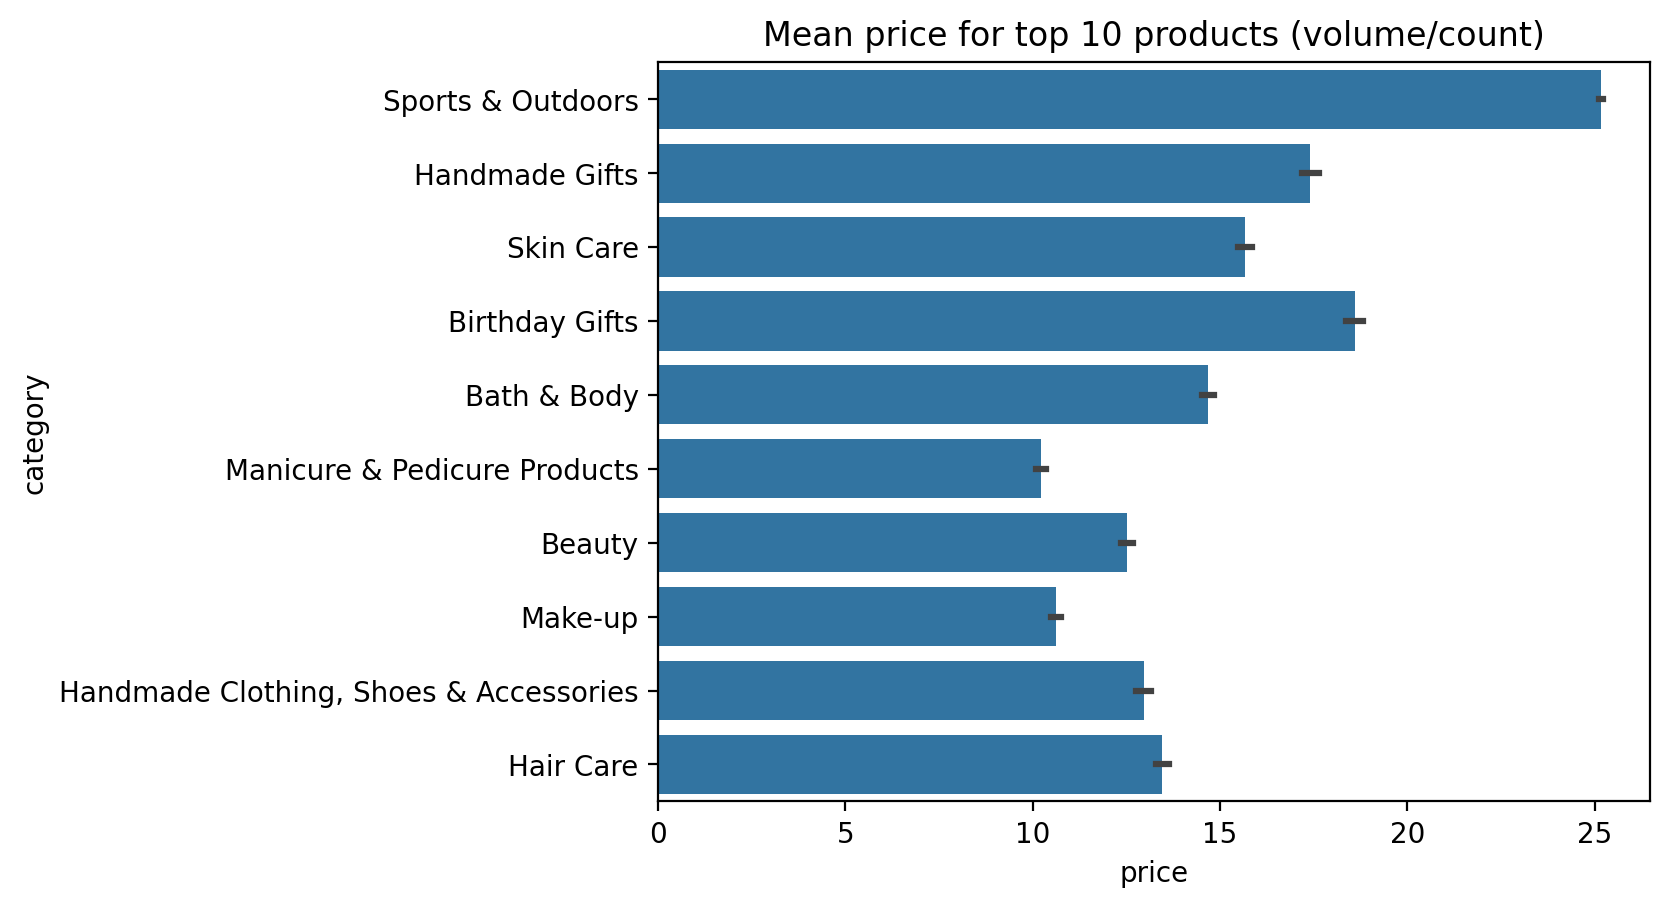

In [22]:
import matplotlib.pyplot as plt

ax = sns.barplot(top_10_df, y="category", x= "price", estimator="mean")
ax.set_title("Mean price for top 10 products (volume/count)")
plt.show()

In [23]:
top_20_most_expensive = filtered_df.groupby("category").mean().sort_values("price", ascending = False)[:10]
display(top_20_most_expensive.reset_index()[["category", "price"]])


,category,price
0,Motherboards,68.772432
1,Boxing Shoes,67.417803
2,Desktop PCs,66.915562
3,Tablets,66.552971
4,Graphics Cards,65.103509
5,Digital Frames,60.745129
6,Streaming Clients,60.241803
7,Hockey Shoes,60.094796
8,Computer Cases,58.339884
9,Skiing Poles,57.867770


In [24]:
print(f"The price category that tends to have the highest mean price is {top_20_most_expensive.iloc[0].name} with a mean price of {round(top_20_most_expensive.iloc[0].price, 2)} pounds.")

The price category that tends to have the highest mean price is Motherboards with a mean price of 68.77 pounds.


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [25]:
# Ratings of top 10 categories based on count (top_10_cat)
#  - Filtered price outliers
#  - Filtered products with no rating (star = 0)

ratings = filtered_df[filtered_df.stars !=0]

ratings_top_10 = ratings[ratings.category.isin(top_10_cat)]
ratings_top_10


,uid,stars,reviews,price,boughtInLastMonth,category
82163,89483,4.2,3116,6.49,0,Sports & Outdoors
82164,89484,4.2,2594,49.99,0,Sports & Outdoors
82167,89487,4.5,9879,16.98,0,Sports & Outdoors
82168,89488,4.7,1223,19.95,0,Sports & Outdoors
82169,89489,4.2,55,49.99,0,Sports & Outdoors
...,...,...,...,...,...,...
2397634,2767899,4.0,1,71.65,0,Sports & Outdoors
2397652,2767930,4.4,37,26.38,0,Sports & Outdoors
2429090,2806952,4.3,3,59.86,0,Sports & Outdoors
2437153,2818782,4.2,554,14.99,0,Sports & Outdoors


<Axes: xlabel='stars', ylabel='category'>

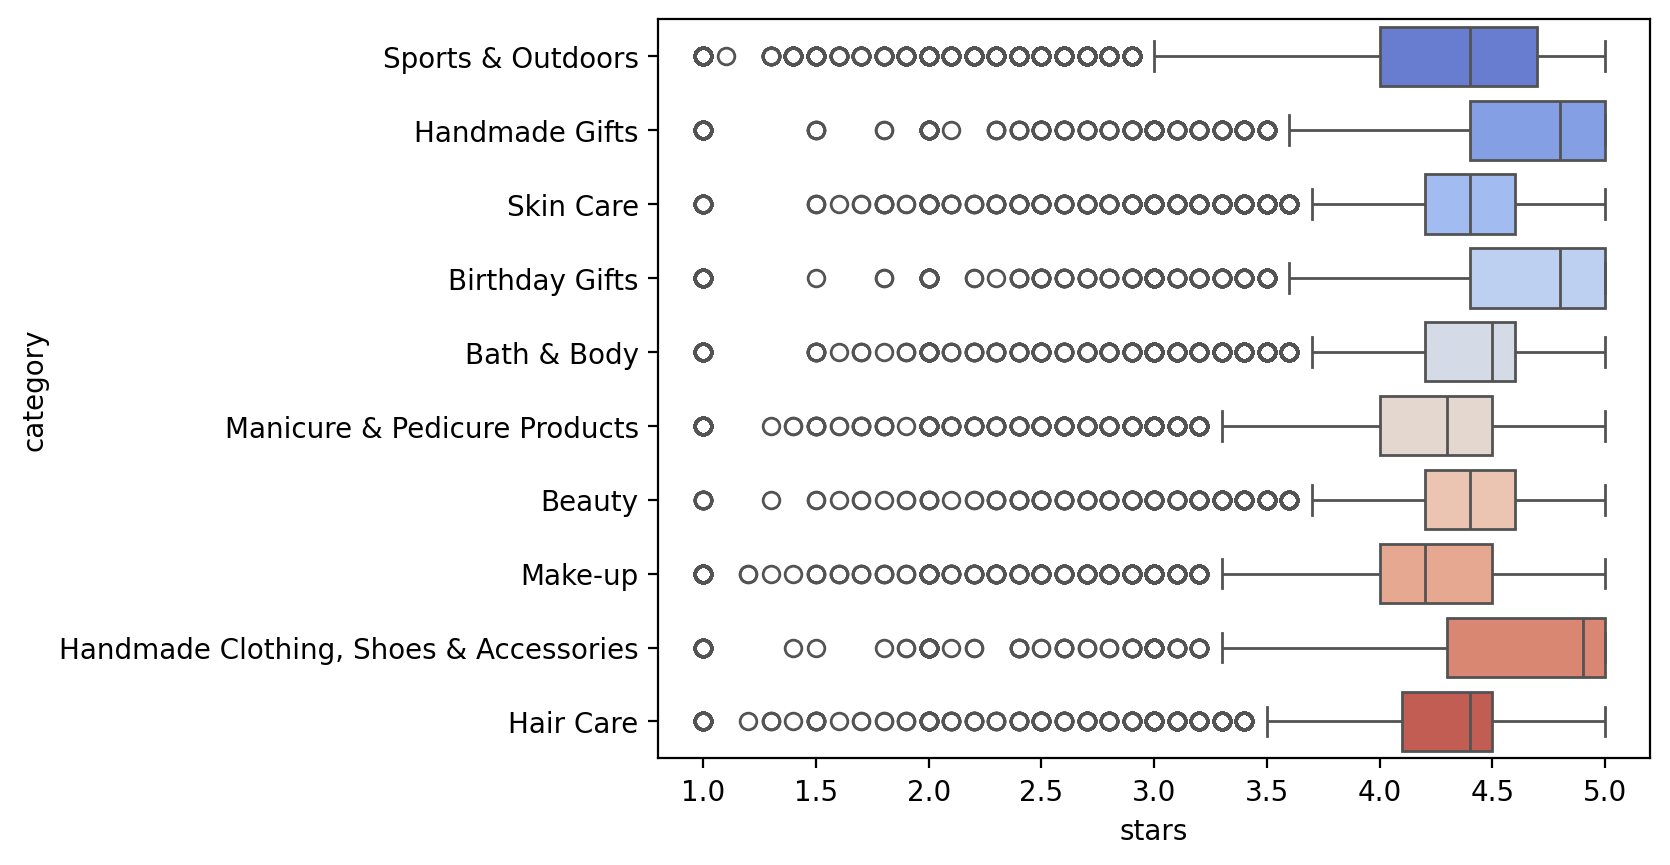

In [26]:
sns.boxplot(ratings_top_10, y = "category", x = "stars", palette="coolwarm", hue = "category", legend=False)

In [27]:
# Highest Median among all dataset (filtering out the price outliers and products without rating)
top_10_median_ratings = ratings[["category", "stars"]].groupby("category").median().sort_values( "stars", ascending = False)[:10]
top_10_median_ratings

,stars
category,
Made in Italy Handmade,5.0
Handmade Baby Products,5.0
Handmade Artwork,5.0
Handmade Kitchen & Dining,4.9
"Handmade Clothing, Shoes & Accessories",4.9
Handmade Gifts,4.8
Birthday Gifts,4.8
Handmade Home Décor,4.8
Handmade Home & Kitchen Products,4.7


In [28]:
from IPython.display import Markdown

top_categories = ", ".join(top_10_median_ratings.index.to_list())
n_handmade = sum([1 if "handmade" in item.lower() else 0 for item in top_10_median_ratings.index.to_list()])
rating_range = top_10_median_ratings.stars.max() - top_10_median_ratings.stars.min()
report = f"""
### 
The 10 categories with highest median ratings, excluding the products with outlier prices, were {top_categories}.
A important insight we can extract from the analysis is that {n_handmade} out of 10 products are described as handmade.
Since this is a strong incidence, there might be a correlation between the item being handmade and having higher ratings.
Additionally, there is a small range of the ratings in the top 10, {round(rating_range, 2)}, which represent really strong evaluations.
"""
display(Markdown(report))


### 
The 10 categories with highest median ratings, excluding the products with outlier prices, were Made in Italy Handmade, Handmade Baby Products, Handmade Artwork, Handmade Kitchen & Dining, Handmade Clothing, Shoes & Accessories, Handmade Gifts, Birthday Gifts, Handmade Home Décor, Handmade Home & Kitchen Products, Gifts for Him.
A important insight we can extract from the analysis is that 8 out of 10 products are described as handmade.
Since this is a strong incidence, there might be a correlation between the item being handmade and having higher ratings.
Additionally, there is a small range of the ratings in the top 10, 0.3, which represent really strong evaluations.


---

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

